# 01 · Exploratory analysis: credit default and card fraud

**Summary.** Credit: 30,000 cardholders, 22.1% default on the October 2005 payment. Repayment behaviour dominates:
accounts two months late in September default at 69% (95% CI 67-71%) against 13% for revolvers, and only 24% of past-due
accounts cure in any month. The status codes -2/-1/0 are undocumented behaviours (inactive, paid in full, revolving), and
"one month late" exists only on the latest statement, so status is treated as a category. Information value puts
September status (0.87), months late (0.86) and worst status (0.78) far above the demographics (sex 0.01, age 0.02). The
demographics are excluded, but the behavioural inputs still carry a little information about sex (AUC 0.61), so the
scorecard gets a fairness check at its cutoff. Fraud: 492 frauds in 284,807 transactions (0.17%), with the rate up to 10x
higher in the small hours and highest on sub-1 card-testing amounts. Six PCA components separate fraud with
single-feature AUCs above 0.9. The surprise is drift: component V3 flips sign at midnight between the two days (PSI
1.4), so the anonymised inputs encode the calendar. Forward-in-time validation and daily PSI monitoring are requirements,
not options.

In [1]:
import os, sys, warnings
os.environ.setdefault("OMP_NUM_THREADS", "4")      # other projects share this laptop: cap OpenMP/BLAS threads
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ds" / "dskit").exists())
sys.path.insert(0, str(ROOT / "ds"))
warnings.simplefilter("ignore")              # library warnings print local paths into the outputs
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from dskit import set_style, PALETTE, headline, savefig, audit, eda, evaluate, explain, select, report
import features as F
set_style(); pd.set_option("display.float_format", lambda v: f"{v:,.4f}"); pd.set_option("display.width", 160)
FIG, METRICS, SEED = ROOT / "ds" / "figures", ROOT / "ds" / "reports" / "metrics.json", 42

## 1. Business understanding

Two decisions an issuer takes every month, each served by one model in this repo.

| | Behavioural PD (UCI, 30,000 cardholders) | Transaction fraud (ULB, 284,807 transactions) |
|---|---|---|
| **Decision** | Which existing accounts get a credit-line review (decrease or freeze) or an early collections call | Which transactions go to the analyst review queue |
| **Unit** | Cardholder, scored at the September 2005 statement | One card transaction |
| **Target and window** | Default on the October 2005 payment (one month ahead) | Confirmed fraud label on the transaction |
| **Action** | Accounts scoring below a cutoff get the review | The riskiest k% of transactions are held for an analyst |
| **Success metric** | Share of defaults and of expected loss caught per account actioned; Gini and KS for ranking | Fraud caught (count and amount) at a fixed review budget; precision of the queue |
| **Money** | Expected loss = PD x exposure at default x loss given default | Fraud amount stopped minus analyst cost per alert |
| **Constraints** | No protected attributes as inputs; every adverse action needs stated reasons; monotone, explainable behaviour | Analyst capacity of roughly 0.1-0.5% of volume; the model only ever sees the past |

This notebook audits both sources, measures how the target moves with each candidate input, and ends with the changes
the evidence forces on the modelling plan.

## 2. Credit data: audit

The UCI file has one row per cardholder: credit limit, four demographic fields, six monthly repayment-status codes,
six bill amounts and six payment amounts (April to September 2005, NT$), and the October default flag.

In [2]:
u = F.load_uci(ROOT)
y = u["Default"]
print(f"{len(u):,} cardholders, {u.shape[1]} columns, default rate {y.mean():.1%}")
audit.profile(u)

30,000 cardholders, 25 columns, default rate 22.1%


,dtype,non_null,missing_pct,unique,min,median,max,top,zeros_pct
column,,,,,,,,,
ID,int64,30000,0.0000,30000,1,"15,000.5000",30000,None,0.0000
LIMIT_BAL,int64,30000,0.0000,81,10000,"140,000.0000",1000000,None,0.0000
SEX,int64,30000,0.0000,2,1,2.0000,2,None,0.0000
EDUCATION,int64,30000,0.0000,7,0,2.0000,6,None,0.0500
MARRIAGE,int64,30000,0.0000,4,0,2.0000,3,None,0.1800
AGE,int64,30000,0.0000,56,21,34.0000,79,None,0.0000
PAY_1,int64,30000,0.0000,11,-2,0.0000,8,None,49.1200
PAY_2,int64,30000,0.0000,11,-2,0.0000,8,None,52.4300
PAY_3,int64,30000,0.0000,11,-2,0.0000,8,None,52.5500


IDs unique: True | rows identical apart from ID: 35 | rows sharing an identical feature profile: 108
Of those, share with all six bills = 0: 90%


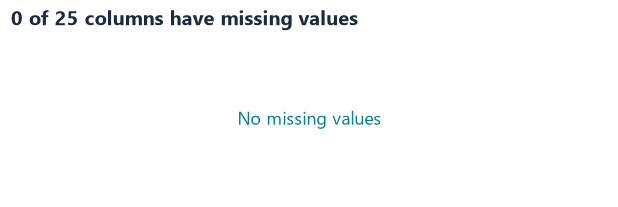

In [3]:
dup = audit.duplicates(u.drop(columns="ID"))
dup_feat = int(u.drop(columns=["ID", "Default"]).duplicated(keep=False).sum())
zero_hist = u.loc[u.drop(columns=["ID", "Default"]).duplicated(keep=False)]
print("IDs unique:", u["ID"].is_unique, "| rows identical apart from ID:", dup["exact_duplicate_rows"],
      "| rows sharing an identical feature profile:", dup_feat)
print("Of those, share with all six bills = 0:", f"{(zero_hist[[f'BILL_AMT{k}' for k in range(1, 7)]] == 0).all(axis=1).mean():.0%}")
fig, ax = plt.subplots(figsize=(7, 1.8)); audit.plot_missing(u, ax=ax); plt.show()

**Duplicates.** IDs are unique. The rows that share a full feature profile are almost all dormant accounts with every bill
at zero, which is a real and common pattern, not a load error. They stay in.

### Undocumented codes

The data dictionary documents EDUCATION 1-4, MARRIAGE 1-3 and repayment status -1 (paid duly) and 1-9 (months of delay).
The file also contains EDUCATION 0, 5 and 6, MARRIAGE 0, and repayment status -2 and 0. The bills and payments behind
each status code show what the codes mean.

In [4]:
codes = pd.concat({
    "EDUCATION": u.groupby("EDUCATION")["Default"].agg(rows="size", default_rate="mean"),
    "MARRIAGE": u.groupby("MARRIAGE")["Default"].agg(rows="size", default_rate="mean")})
codes["documented"] = [lv in {1, 2, 3, 4} if f == "EDUCATION" else lv in {1, 2, 3} for f, lv in codes.index]
codes

rows  default_rate  documented
EDUCATION 0     14        0.0000       False
          1  10585        0.1923        True
          2  14030        0.2373        True
          3   4917        0.2516        True
          4    123        0.0569        True
          5    280        0.0643       False
          6     51        0.1569       False
MARRIAGE  0     54        0.0926       False
          1  13659        0.2347        True
          2  15964        0.2093        True
          3    323        0.2601        True

In [5]:
st = u.groupby("PAY_1").agg(rows=("Default", "size"), default_rate=("Default", "mean"),
                            median_bill=("BILL_AMT1", "median"), median_payment=("PAY_AMT1", "median"),
                            share_zero_bill=("BILL_AMT1", lambda s: (s == 0).mean()))
st.index.name = "September status code"
st

,rows,default_rate,median_bill,median_payment,share_zero_bill
September status code,,,,,
-2,2759,0.1323,"1,179.0000","1,131.0000",0.2515
-1,5686,0.1678,"2,739.5000","1,732.5000",0.0004
0,14737,0.1281,"49,605.0000","3,000.0000",0.0000
1,3688,0.3395,"4,606.5000",0.0000,0.3557
2,2667,0.6914,"41,632.0000","2,000.0000",0.0000
3,322,0.7578,"18,354.0000",0.0000,0.0000
4,76,0.6842,"31,633.0000",0.0000,0.0000
5,26,0.5000,"39,752.5000",0.0000,0.0000
6,11,0.5455,"71,310.0000",0.0000,0.0000


In [6]:
late1 = pd.Series({f"{F.MONTHS[k - 1]:%b}": int((u[f"PAY_{k}"] == 1).sum()) for k in range(1, 7)}, name="accounts with status 1 (one month late)")
late1.to_frame().T

,Sep,Aug,Jul,Jun,May,Apr
accounts with status 1 (one month late),3688,28,4,2,0,0


* **Status -2, -1 and 0 are not "paid on time" variants.** Accounts coded -2 have a median September bill of NT$1,179 and
  are inactive; -1 accounts pay their (small) bill in full; 0 accounts carry a median bill of NT$49,605 and pay a fraction
  of it, which is revolving credit, not delinquency. The ETL labels them "No use", "Paid in full" and "Revolving", and the
  default rate confirms they are three different behaviours (13%, 17% and 13%).
* **"One month late" exists almost only in the latest month**: thousands of accounts in September, a few dozen or none in
  earlier months. Older months jump from "Revolving" straight to "2 months late". So the six status columns are not
  coded identically, and the roll-rate view below uses "any past due" for the earlier months.
* **EDUCATION 0/5/6 and MARRIAGE 0** cover a few hundred rows with low default rates. They are demographic fields that the
  models will not use, so they are grouped as "Other / unknown" for reporting only.

In [7]:
neg = pd.DataFrame({f"{F.MONTHS[k - 1]:%b}": {"negative bill": int((u[f"BILL_AMT{k}"] < 0).sum()),
                                               "bill above limit": int((u[f"BILL_AMT{k}"] > u["LIMIT_BAL"]).sum()),
                                               "max bill / limit": float((u[f"BILL_AMT{k}"] / u["LIMIT_BAL"]).max())} for k in range(1, 7)})
neg

,Sep,Aug,Jul,Jun,May,Apr
negative bill,590.0000,669.0000,655.0000,675.0000,655.0000,688.0000
bill above limit,"2,115.0000","1,940.0000","1,583.0000","1,018.0000",820.0000,798.0000
max bill / limit,6.4553,6.3805,10.6886,5.1468,4.9355,3.8855


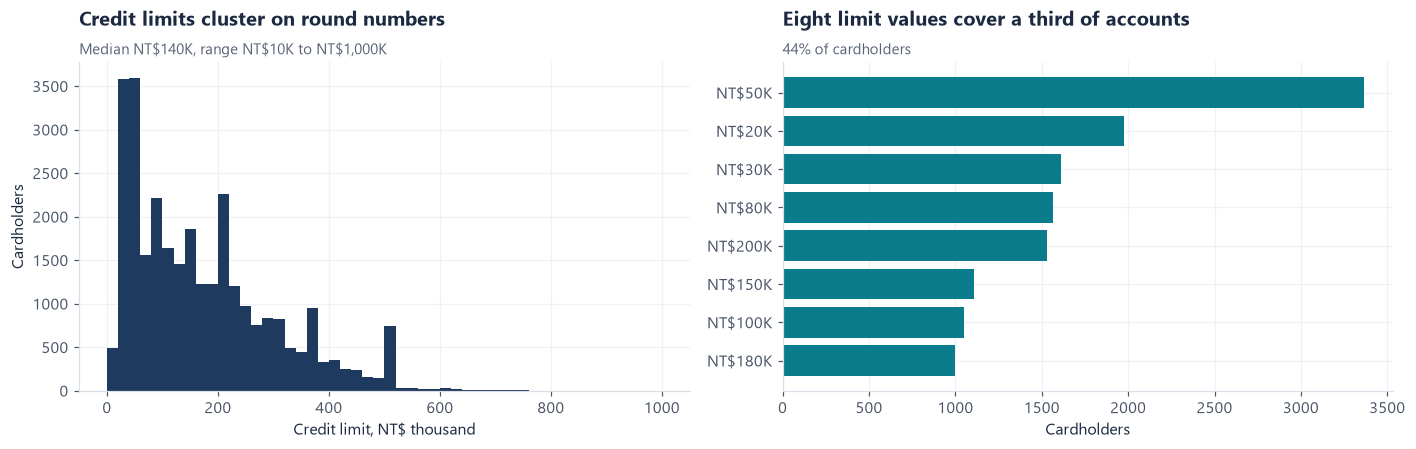

In [8]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.2))
lim = u["LIMIT_BAL"] / 1000
a1.hist(lim, bins=np.arange(0, 1010, 20), color=PALETTE["navy"])
a1.set(xlabel="Credit limit, NT$ thousand", ylabel="Cardholders")
headline(a1, "Credit limits cluster on round numbers", f"Median NT${lim.median():,.0f}K, range NT${lim.min():,.0f}K to NT${lim.max():,.0f}K")
top = (u["LIMIT_BAL"] / 1000).value_counts().head(8)
a2.barh([f"NT${v:,.0f}K" for v in top.index[::-1]], top.values[::-1], color=PALETTE["teal"])
a2.set_xlabel("Cardholders")
headline(a2, "Eight limit values cover a third of accounts", f"{top.sum() / len(u):.0%} of cardholders")
fig.tight_layout(); plt.show()

* **Negative bills** (credit balances from overpayment or refunds) appear in about 2% of accounts each month. Utilisation
  treats them as a zero balance, which is the ETL's choice and the right one for a risk feature.
* **Bills above the limit** are common (over 2,000 accounts in September; the maximum is several times the limit),
  because the bill includes interest and fees. Utilisation is capped at 2x the limit so a few extreme ratios cannot
  dominate a linear model.
* **Limits** are set by the issuer in round steps and are themselves a risk decision: a low limit partly reflects risk the
  issuer already saw. That makes limit a strong but partly circular predictor, which is acceptable for a behavioural
  score used on the same book.

## 3. Credit data: how default moves with each input

Default rate with a 95% Wilson interval (line) over the share of accounts (bars).

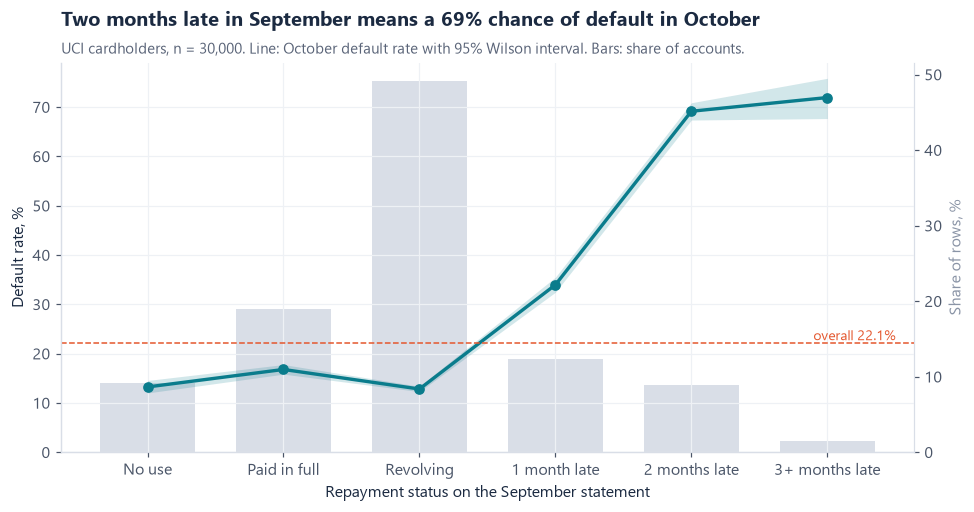

,rows,share,rate,ci_low,ci_high
Status,,,,,
No use,2759,0.0920,0.1323,0.1202,0.1454
Paid in full,5686,0.1895,0.1678,0.1583,0.1777
Revolving,14737,0.4912,0.1281,0.1228,0.1336
1 month late,3688,0.1229,0.3395,0.3244,0.3549
2 months late,2667,0.0889,0.6914,0.6736,0.7087
3+ months late,463,0.0154,0.7192,0.6766,0.7582


In [9]:
d = u.assign(Status=pd.Categorical(F.bucket(u["PAY_1"]), F.BUCKETS, ordered=True))
fig, ax = plt.subplots(figsize=(10, 4.6))
t_status = eda.rate_by(d, "Status", "Default", ax=ax, order=F.BUCKETS, rate_label="Default rate",
                       xlabel="Repayment status on the September statement",
                       title="Two months late in September means a 69% chance of default in October",
                       subtitle="UCI cardholders, n = 30,000. Line: October default rate with 95% Wilson interval. Bars: share of accounts.")
_ = savefig(fig, "01-default-by-status", FIG); plt.show()
t_status

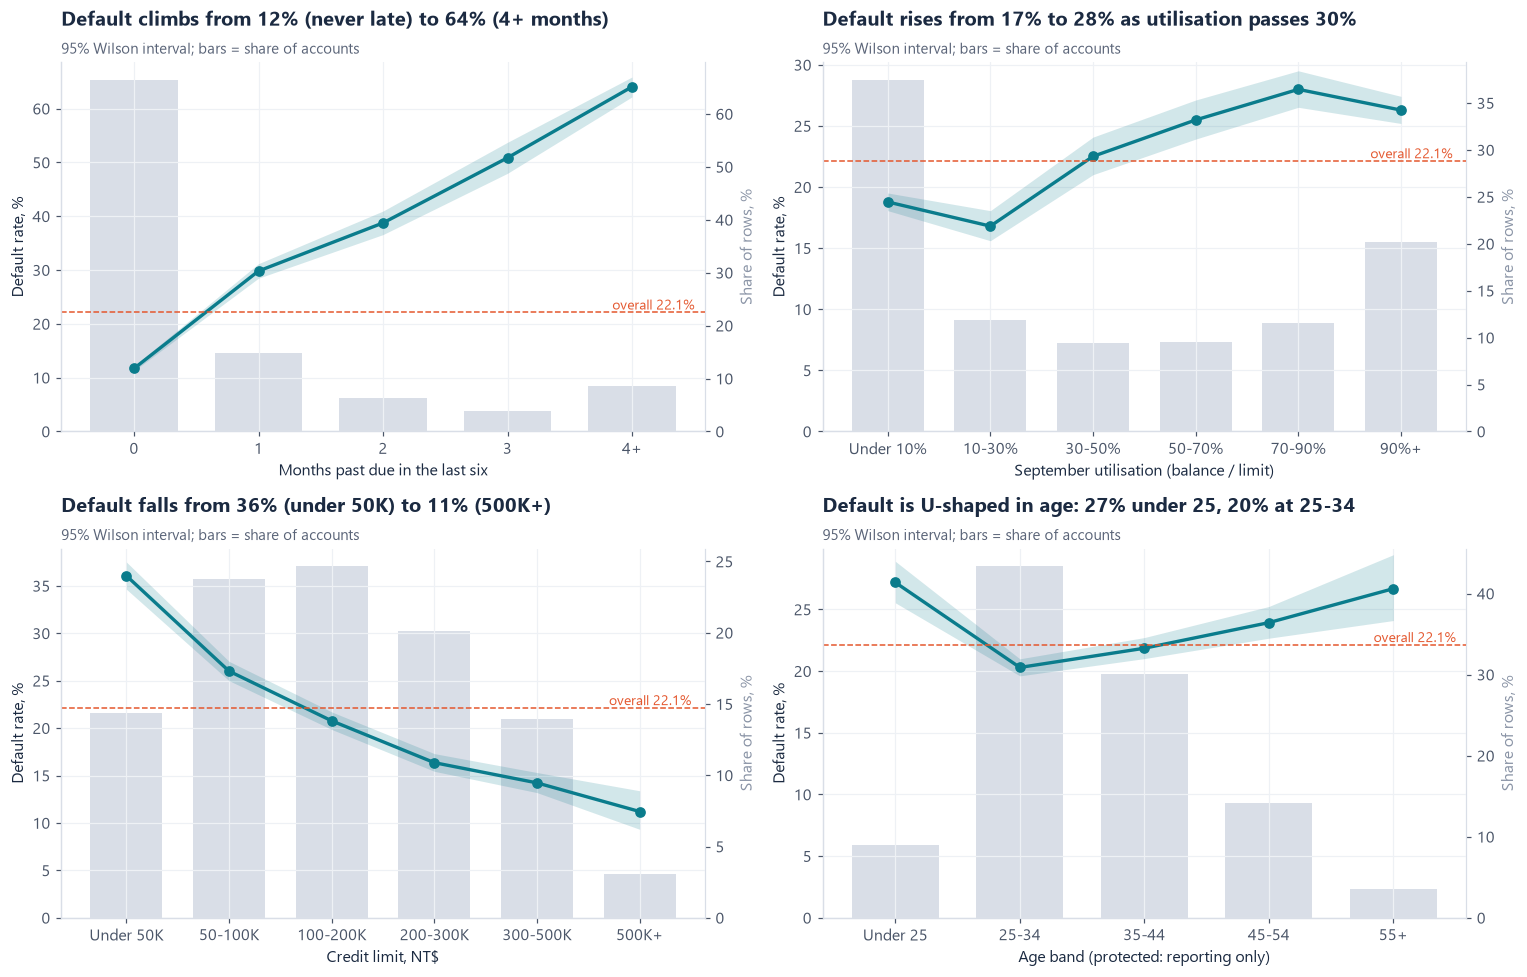

rows   rate  ci_low  ci_high
driver     level                                   
MonthsLate 0          19931 0.1171  0.1127   0.1216
           1           4426 0.2982  0.2849   0.3119
           2           1899 0.3876  0.3659   0.4097
           3           1154 0.5087  0.4798   0.5374
           4+          2590 0.6405  0.6219   0.6588
UtilBand   Under 10%  11239 0.1878  0.1807   0.1952
           10-30%      3553 0.1680  0.1561   0.1807
           30-50%      2834 0.2251  0.2101   0.2409
           50-70%      2852 0.2549  0.2393   0.2712
           70-90%      3472 0.2800  0.2653   0.2951
           90%+        6050 0.2630  0.2520   0.2742
LimitBand  Under 50K   4311 0.3607  0.3465   0.3752
           50-100K     7139 0.2601  0.2501   0.2704
           100-200K    7400 0.2077  0.1986   0.2171
           200-300K    6033 0.1636  0.1545   0.1731
           300-500K    4189 0.1423  0.1320   0.1532
           500K+        928 0.1121  0.0934   0.1340
AgeBand    Under 25    2685 0.2719  0.2554   0.2890
           25-34      13011 0.2030  0.1962   0.2100
           35-44       9018 0.2186  0.2102   0.2272
           45-54       4233 0.2393  0.2267   0.2524
           55+         1053 0.2669  0.2410   0.2944

In [10]:
d["Utilisation"] = (u["BILL_AMT1"].clip(lower=0) / u["LIMIT_BAL"]).clip(0, 2)
d["UtilBand"] = F.band(d["Utilisation"], F.UTIL_BANDS)
d["LimitBand"] = F.band(u["LIMIT_BAL"], F.LIMIT_BANDS)
d["AgeBand"] = F.band(u["AGE"], F.AGE_BANDS)
d["MonthsLate"] = (u[[f"PAY_{k}" for k in range(1, 7)]] >= 1).sum(axis=1).clip(upper=4).map(lambda v: "4+" if v == 4 else str(v))
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
tabs = {}
for ax, (col, order, xl, ttl) in zip(axes.flat, [
        ("MonthsLate", ["0", "1", "2", "3", "4+"], "Months past due in the last six", "Default climbs from 12% (never late) to 64% (4+ months)"),
        ("UtilBand", F.UTIL_BANDS[1], "September utilisation (balance / limit)", "Default rises from 17% to 28% as utilisation passes 30%"),
        ("LimitBand", F.LIMIT_BANDS[1], "Credit limit, NT$", "Default falls from 36% (under 50K) to 11% (500K+)"),
        ("AgeBand", F.AGE_BANDS[1], "Age band (protected: reporting only)", "Default is U-shaped in age: 27% under 25, 20% at 25-34")]):
    tabs[col] = eda.rate_by(d, col, "Default", ax=ax, order=order, rate_label="Default rate", xlabel=xl, title=ttl, subtitle="95% Wilson interval; bars = share of accounts")
fig.tight_layout(); plt.show()
pd.concat(tabs, names=["driver", "level"])[["rows", "rate", "ci_low", "ci_high"]]

### Roll rates across the six statements

How accounts move between delinquency buckets from one month to the next, pooled over the five transitions
(April->May ... August->September). This is the collections view: where do accounts cure, and where do they roll forward?

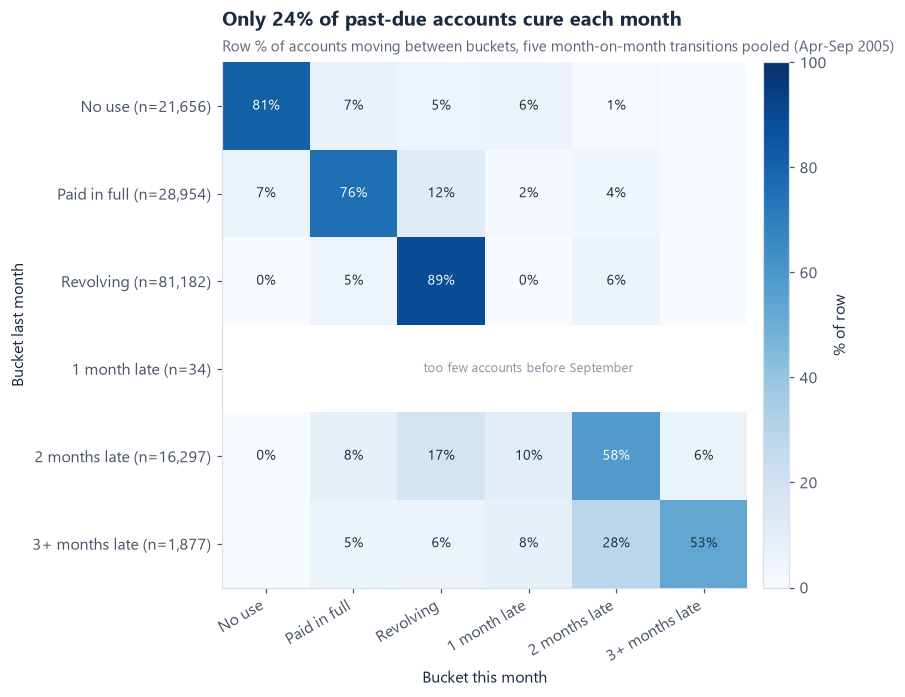

Pooled monthly cure rate from any past-due bucket: 23.8%; roll forward from 2 months late to 3+: 6.3%


col_0,No use,Paid in full,Revolving,1 month late,2 months late,3+ months late
row_0,,,,,,
No use,81.3000,6.8000,5.0000,5.7000,1.2000,0.0000
Paid in full,6.6000,75.7000,12.0000,2.1000,3.6000,0.0000
Revolving,0.0000,5.1000,88.9000,0.0000,6.1000,0.0000
1 month late,NaN,NaN,NaN,NaN,NaN,NaN
2 months late,0.1000,8.0000,17.3000,10.3000,58.0000,6.3000
3+ months late,0.0000,5.1000,5.5000,8.1000,28.2000,53.1000


In [11]:
tr = F.transitions(u)
order = F.BUCKETS
mat = pd.crosstab(pd.Categorical(tr["from"], order), pd.Categorical(tr["to"], order), normalize="index")
counts = pd.crosstab(pd.Categorical(tr["from"], order), pd.Categorical(tr["to"], order))
row_n = counts.sum(axis=1)
thin = row_n < 100                                     # "1 month late" barely exists before September (see audit)
mat.loc[thin] = np.nan
fig, ax = plt.subplots(figsize=(9, 6.2))
im = ax.imshow(mat.values * 100, cmap="Blues", vmin=0, vmax=100)
for i in range(len(order)):
    for j in range(len(order)):
        v = mat.values[i, j] * 100
        if thin.iloc[i]:
            if j == len(order) // 2:
                ax.text(j, i, "too few accounts before September", ha="center", va="center", fontsize=8.5, color=PALETTE["grey"])
            continue
        ax.text(j, i, f"{v:.0f}%" if counts.values[i, j] > 0 else "", ha="center", va="center", fontsize=9, color="white" if v > 55 else PALETTE["ink"])
ax.set_xticks(range(len(order)), order, rotation=30, ha="right")
ax.set_yticks(range(len(order)), [f"{b} (n={n:,})" for b, n in zip(order, row_n)])
ax.set_xlabel("Bucket this month"); ax.set_ylabel("Bucket last month"); ax.grid(False)
past_due = ["1 month late", "2 months late", "3+ months late"]
from_pd = tr[tr["from"].isin(past_due)]
cure = (~from_pd["to"].isin(past_due)).mean()
headline(ax, f"Only {cure:.0%} of past-due accounts cure each month",
         "Row % of accounts moving between buckets, five month-on-month transitions pooled (Apr-Sep 2005)")
plt.colorbar(im, ax=ax, fraction=0.035, pad=0.02, label="% of row")
_ = savefig(fig, "01-roll-rates", FIG); plt.show()
print(f"Pooled monthly cure rate from any past-due bucket: {cure:.1%}; roll forward from 2 months late to 3+: {mat.loc['2 months late', '3+ months late']:.1%}")
(mat * 100).round(1)

### Information value: which inputs separate defaulters from non-defaulters?

Weight of evidence / information value on the ETL's behavioural features (decile bins), with the protected attributes
shown for reference only. IV above 0.3 is strong; above 0.5 usually means a feature that is close to the outcome itself.

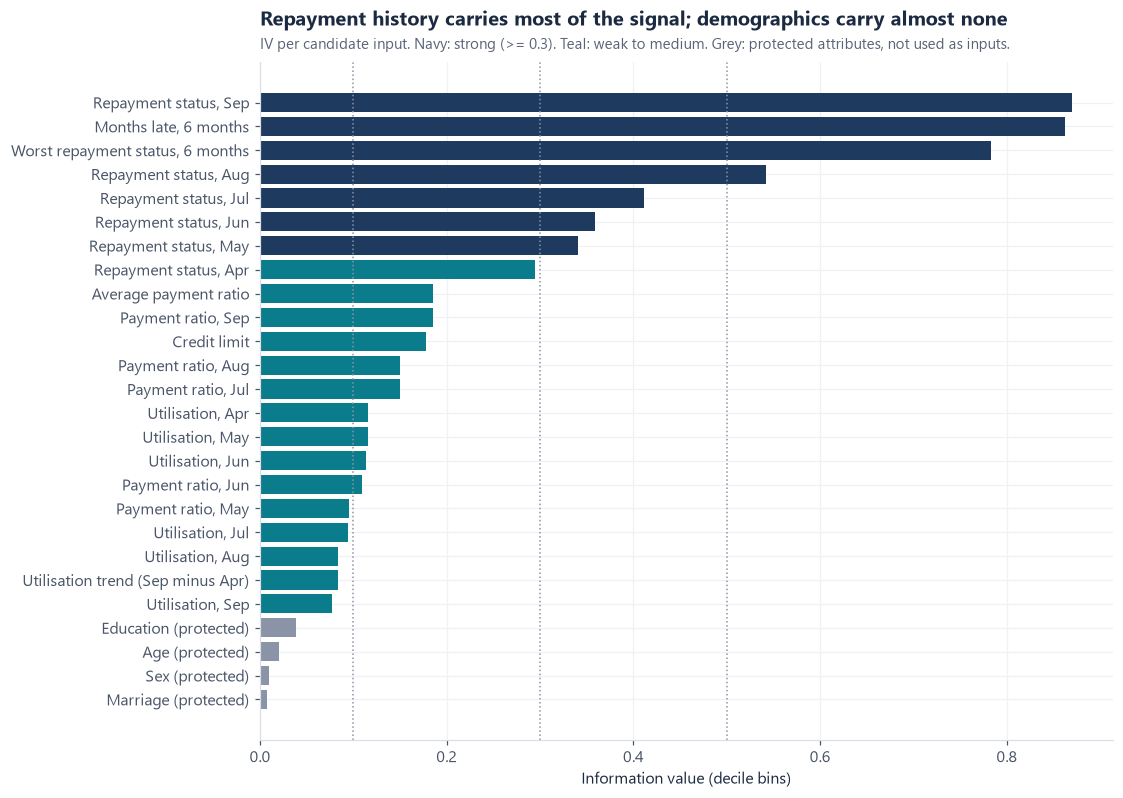

,iv,strength
feature,,
status_1,0.8697,suspicious (check leakage)
months_late,0.8619,suspicious (check leakage)
max_status,0.7835,suspicious (check leakage)
status_2,0.5424,suspicious (check leakage)
status_3,0.4109,strong
status_4,0.3592,strong
status_5,0.3407,strong
status_6,0.2944,medium
avg_payratio,0.1855,medium


In [12]:
X = F.pd_features(u)
Xi = X.assign(Default=y, SEX=u["SEX"], AGE=u["AGE"], MARRIAGE=u["MARRIAGE"], EDUCATION=u["EDUCATION"])
iv = eda.iv_table(Xi, F.PD_FEATURES + F.PROTECTED, "Default")
iv["label"] = [F.LABELS.get(f, f.title() + " (protected)") for f in iv.index]
fig, ax = plt.subplots(figsize=(10, 8))
t = iv[::-1]
ax.barh(t["label"], t["iv"], color=[PALETTE["grey"] if f in F.PROTECTED else PALETTE["navy"] if v >= 0.3 else PALETTE["teal"] for f, v in zip(t.index, t["iv"])])
for x in (0.1, 0.3, 0.5):
    ax.axvline(x, ls=":", color=PALETTE["grey"], lw=1)
ax.set_xlabel("Information value (decile bins)")
headline(ax, "Repayment history carries most of the signal; demographics carry almost none",
         "IV per candidate input. Navy: strong (>= 0.3). Teal: weak to medium. Grey: protected attributes, not used as inputs.")
_ = savefig(fig, "01-information-value", FIG); plt.show()
iv[["iv", "strength"]]

Repayment status IVs above 0.5 would normally trigger a leakage check. Here the timing is clean: every status code is
reported on a statement dated April to September, and the target is the October payment. The status simply is the
strongest behavioural signal a card issuer has. The single-feature AUC screen below confirms nothing is near-perfect.

In [13]:
leak = audit.leakage_screen(X.assign(Default=y), F.PD_FEATURES, "Default")
leak.head(8)

,single_feature_auc,direction,review
feature,,,
months_late,0.7261,+,
max_status,0.7077,+,
status_1,0.6897,+,
status_2,0.6386,+,
status_3,0.6243,+,
limit,0.6178,-,
avg_payratio,0.6129,-,
status_4,0.6097,+,


### The six bill amounts move together

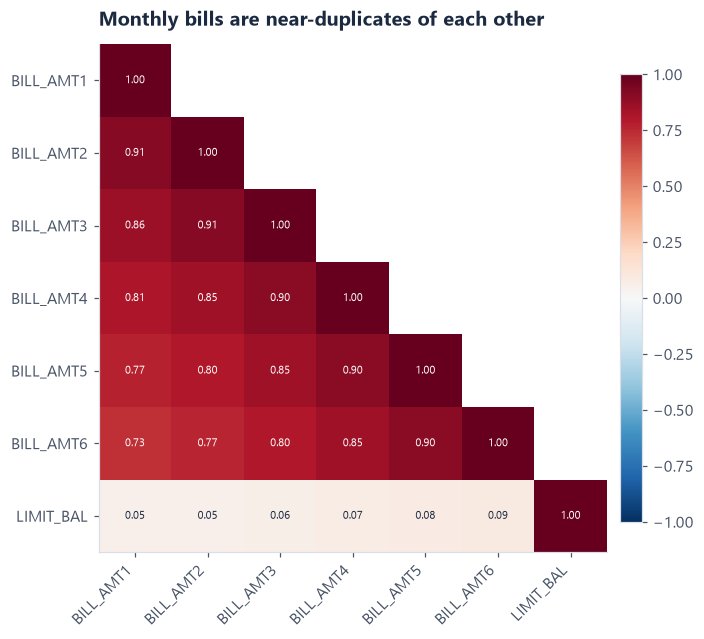

,feature_a,feature_b,rho
0,BILL_AMT1,BILL_AMT2,0.9111
3,BILL_AMT2,BILL_AMT3,0.9077
6,BILL_AMT3,BILL_AMT4,0.9036
9,BILL_AMT4,BILL_AMT5,0.9028
11,BILL_AMT5,BILL_AMT6,0.9021
1,BILL_AMT1,BILL_AMT3,0.8577
7,BILL_AMT3,BILL_AMT5,0.8485
4,BILL_AMT2,BILL_AMT4,0.8484
10,BILL_AMT4,BILL_AMT6,0.8480
2,BILL_AMT1,BILL_AMT4,0.8073


In [14]:
bills = [f"BILL_AMT{k}" for k in range(1, 7)]
fig, ax = plt.subplots(figsize=(7.5, 6))
c = eda.corr_heatmap(u, bills + ["LIMIT_BAL"], ax=ax, title="Monthly bills are near-duplicates of each other")
plt.show()
eda.high_correlation_pairs(u, bills + [f"PAY_AMT{k}" for k in range(1, 7)] + ["LIMIT_BAL"], threshold=0.8)

Adjacent bills correlate above 0.9 (Spearman). Raw bill amounts would add six near-copies of one signal, so the ETL
expresses them as utilisation (bill / limit), a payment ratio (payment / previous bill) and a six-month utilisation
trend. The scorecard in notebook 02 goes further and keeps one characteristic per family.

### Protected attributes

SEX, AGE, MARRIAGE and EDUCATION are excluded from every model on purpose. Two questions remain: do the groups differ in
default rate (they will then differ in approval rate under any accurate score), and do the behavioural inputs act as
proxies for them?

In [15]:
prot = []
for col, mapping in [("SEX", {1: "Male", 2: "Female"}), ("MARRIAGE", {1: "Married", 2: "Single", 3: "Other", 0: "Other"}),
                     ("AgeBand", None)]:
    s = d[col] if mapping is None else u[col].map(mapping)
    g = pd.DataFrame({"group": s, "y": y}).groupby("group")["y"].agg(["sum", "count"])
    lo, hi = eda.wilson(g["sum"], g["count"])
    prot.append(pd.DataFrame({"attribute": col, "accounts": g["count"], "default_rate": g["sum"] / g["count"], "ci_low": lo, "ci_high": hi}))
pd.concat(prot)

,attribute,accounts,default_rate,ci_low,ci_high
group,,,,,
Female,SEX,18112,0.2078,0.2019,0.2137
Male,SEX,11888,0.2417,0.2341,0.2495
Married,MARRIAGE,13659,0.2347,0.2277,0.2419
Other,MARRIAGE,377,0.2361,0.1960,0.2815
Single,MARRIAGE,15964,0.2093,0.2030,0.2157
25-34,AgeBand,13011,0.2030,0.1962,0.2100
35-44,AgeBand,9018,0.2186,0.2102,0.2272
45-54,AgeBand,4233,0.2393,0.2267,0.2524
55+,AgeBand,1053,0.2669,0.2410,0.2944


In [16]:
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.model_selection import cross_val_score, StratifiedKFold, KFold
proxy_sex = cross_val_score(HistGradientBoostingClassifier(max_iter=200, random_state=SEED), X, u["SEX"] == 2,
                            cv=StratifiedKFold(3, shuffle=True, random_state=SEED), scoring="roc_auc").mean()
proxy_age = cross_val_score(HistGradientBoostingRegressor(max_iter=200, random_state=SEED), X, u["AGE"],
                            cv=KFold(3, shuffle=True, random_state=SEED), scoring="r2").mean()
print(f"Behavioural features -> sex: cross-validated AUC {proxy_sex:.3f} (0.5 = no information)")
print(f"Behavioural features -> age: cross-validated R^2 {proxy_age:.3f}")
print("Spearman rho, age vs credit limit:", round(u["AGE"].corr(u["LIMIT_BAL"], method="spearman"), 3))

Behavioural features -> sex: cross-validated AUC 0.607 (0.5 = no information)
Behavioural features -> age: cross-validated R^2 0.036
Spearman rho, age vs credit limit: 0.186


Men default more often than women in this book (24.2% vs 20.8%), and the youngest and oldest age bands default more than
the 25-34 band (27% vs 20%). The behavioural features carry a little information about sex (cross-validated AUC 0.61,
where 0.5 is none) and almost none about age (R² 0.04; the limit rises mildly with age, rho 0.19). Excluding the
attributes is therefore necessary but not sufficient: any accurate score will treat groups with different default rates
differently. Notebook 02 measures approval and bad rates by sex and age band at the chosen cutoff and reports the
adverse-impact ratio.

## 4. Fraud data: audit

284,807 transactions over two days (September 2013). V1-V28 are principal components of confidential original
features; only Time (seconds since the first transaction) and Amount are in their original form.

In [17]:
fr = F.load_fraud(ROOT)
prof = audit.profile(fr.drop(columns=["Day"]))
prof.loc[["Time", "Amount", "Class", "Hour", "V1", "V2", "V14", "V28"]]

,dtype,non_null,missing_pct,unique,min,median,max,top,zeros_pct
column,,,,,,,,,
Time,float64,284807,0.0000,124592,0.0000,"84,692.0000","172,792.0000",None,0.0000
Amount,float64,284807,0.0000,32767,0.0000,22.0000,"25,691.1600",None,0.6400
Class,int64,284807,0.0000,2,0.0000,0.0000,1.0000,None,99.8300
Hour,int64,284807,0.0000,24,0.0000,15.0000,23.0000,None,2.7000
V1,float64,284807,0.0000,275663,-56.4075,0.0181,2.4549,None,0.0000
V2,float64,284807,0.0000,275663,-72.7157,0.0655,22.0577,None,0.0000
V14,float64,284807,0.0000,275663,-19.2143,0.0506,10.5268,None,0.0000
V28,float64,284807,0.0000,275663,-15.4301,0.0112,33.8478,None,0.0000


In [18]:
vstd = fr[F.V_COLS].std()
print(f"V1-V28: means within {fr[F.V_COLS].mean().abs().max():.1e} of zero; standard deviation falls from {vstd.iloc[0]:.2f} (V1) to {vstd.iloc[-1]:.2f} (V28) - the signature of PCA output")
fd = audit.duplicates(fr.drop(columns=["Hour", "Day"]))
dmask = fr.drop(columns=["Hour", "Day"]).duplicated(keep=False)
print(f"Exact duplicate rows: {fd['exact_duplicate_rows']:,} ({fr.loc[dmask, 'Class'].sum()} frauds among the {dmask.sum():,} rows involved)")
n1, n = int(fr["Class"].sum()), len(fr)
lo, hi = eda.wilson(n1, n)
print(f"Fraud: {n1} of {n:,} transactions = {n1 / n:.3%} (95% CI {float(lo):.3%} to {float(hi):.3%}); {n / n1:,.0f} genuine per fraud")
print(f"Zero-amount transactions: {(fr['Amount'] == 0).sum():,}, of which fraud: {fr.loc[fr['Amount'] == 0, 'Class'].sum()}")

V1-V28: means within 4.9e-15 of zero; standard deviation falls from 1.96 (V1) to 0.33 (V28) - the signature of PCA output


Exact duplicate rows: 1,081 (32 frauds among the 1,854 rows involved)
Fraud: 492 of 284,807 transactions = 0.173% (95% CI 0.158% to 0.189%); 579 genuine per fraud
Zero-amount transactions: 1,825, of which fraud: 27


* **No missing values; the V columns are centred PCA scores** with variance ordered by component, as documented.
* **Duplicates**: about a thousand rows are exact copies (same second, amount and components). They look like repeated
  authorisation messages. The ETL keeps them; they are 0.4% of rows and do not change any conclusion, but a production
  pipeline should de-duplicate on a transaction ID, which this public extract does not have.
* **Imbalance**: 1 fraud per ~580 transactions. Accuracy and ROC AUC will look excellent for almost any model, so the
  evaluation in notebook 03 is built on precision-recall and on what an analyst queue of fixed size catches.

### When does fraud happen?

Hour of day is `Time // 3600 mod 24`. That assumes the extract starts near midnight; the volume trough between hours 1
and 6 on both days supports the assumption.

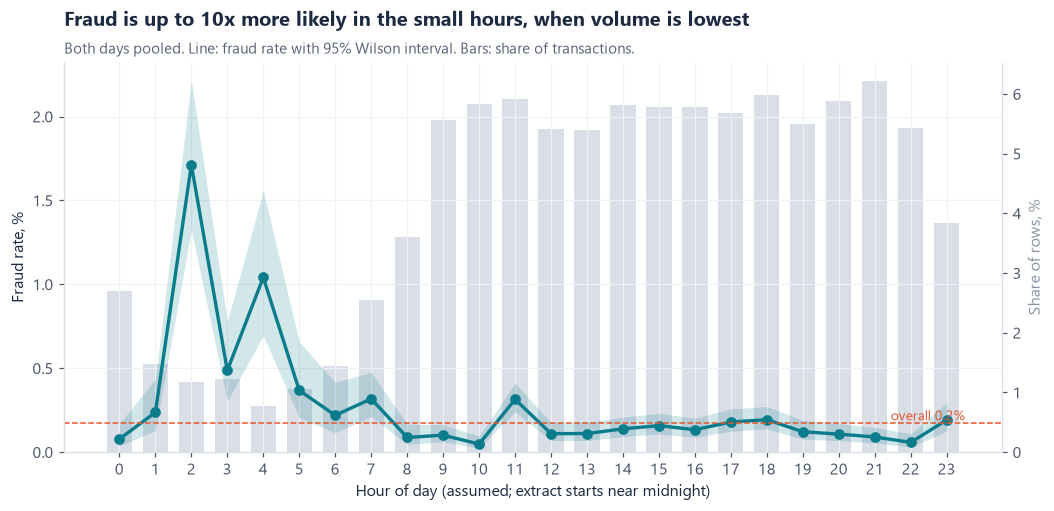

,rows,rate,ci_low,ci_high
Hour,,,,
2,3328,0.0171,0.0132,0.0221
4,2209,0.0104,0.0069,0.0156
3,3492,0.0049,0.0030,0.0078
5,2990,0.0037,0.0021,0.0066
7,7243,0.0032,0.0021,0.0048
11,16856,0.0031,0.0024,0.0041


In [19]:
fig, ax = plt.subplots(figsize=(11, 4.6))
t_hour = eda.rate_by(fr, "Hour", "Class", ax=ax, rate_label="Fraud rate", xlabel="Hour of day (assumed; extract starts near midnight)",
                     title="Fraud is up to 10x more likely in the small hours, when volume is lowest",
                     subtitle="Both days pooled. Line: fraud rate with 95% Wilson interval. Bars: share of transactions.")
ax.set_ylabel("Fraud rate, %")
plt.show()
t_hour[["rows", "rate", "ci_low", "ci_high"]].sort_values("rate", ascending=False).head(6)

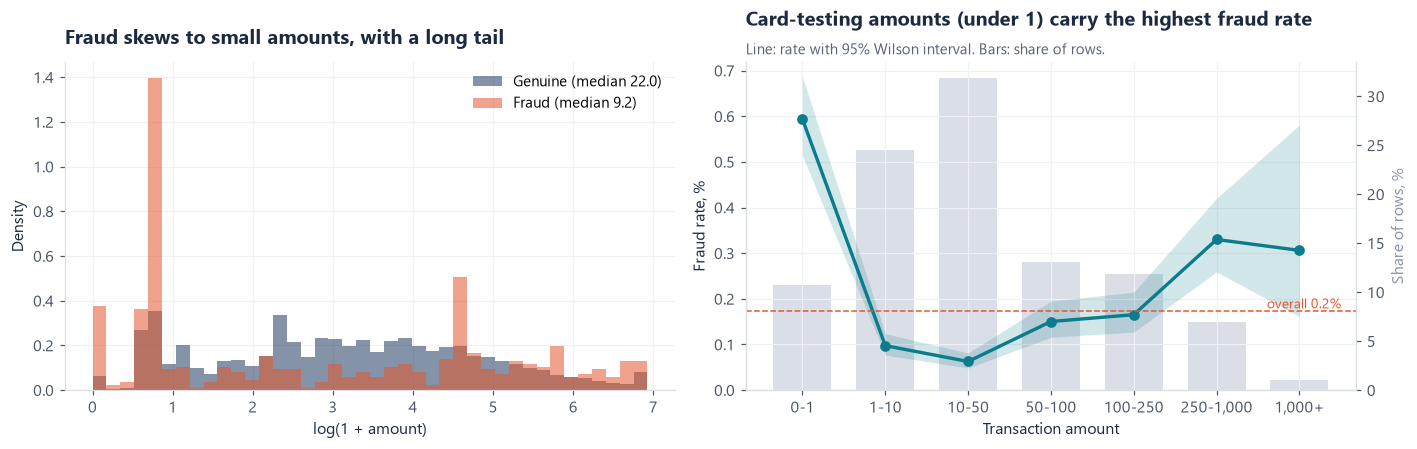

,rows,rate,ci_low,ci_high
AmountBand,,,,
0-1,30492,0.0059,0.0051,0.0069
1-10,69772,0.0010,0.0008,0.0012
10-50,90781,0.0006,0.0005,0.0008
50-100,37254,0.0015,0.0012,0.0020
100-250,33873,0.0017,0.0013,0.0021
"250-1,000",19695,0.0033,0.0026,0.0042
"1,000+",2940,0.0031,0.0016,0.0058


In [20]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.2))
eda.dist_by_target(fr, "Amount", "Class", ax=a1, log=True, labels=("Genuine", "Fraud"), title="Fraud skews to small amounts, with a long tail")
a1.set_xlabel("log(1 + amount)")
amt = fr.assign(AmountBand=pd.cut(fr["Amount"], [-1, 1, 10, 50, 100, 250, 1000, 1e9], labels=["0-1", "1-10", "10-50", "50-100", "100-250", "250-1,000", "1,000+"]))
t_amt = eda.rate_by(amt, "AmountBand", "Class", ax=a2, rate_label="Fraud rate", xlabel="Transaction amount", title="Card-testing amounts (under 1) carry the highest fraud rate")
fig.tight_layout(); plt.show()
t_amt[["rows", "rate", "ci_low", "ci_high"]]

The median fraud is smaller than the median genuine payment, and amounts under 1 have the highest fraud rate (the
classic card-testing pattern: a tiny charge to check a stolen card works). Amount on its own will not find fraud, but it
matters for the money view: the fraud amount at stake in the test window is what the alert budget protects.

### Do the PCA components separate fraud?

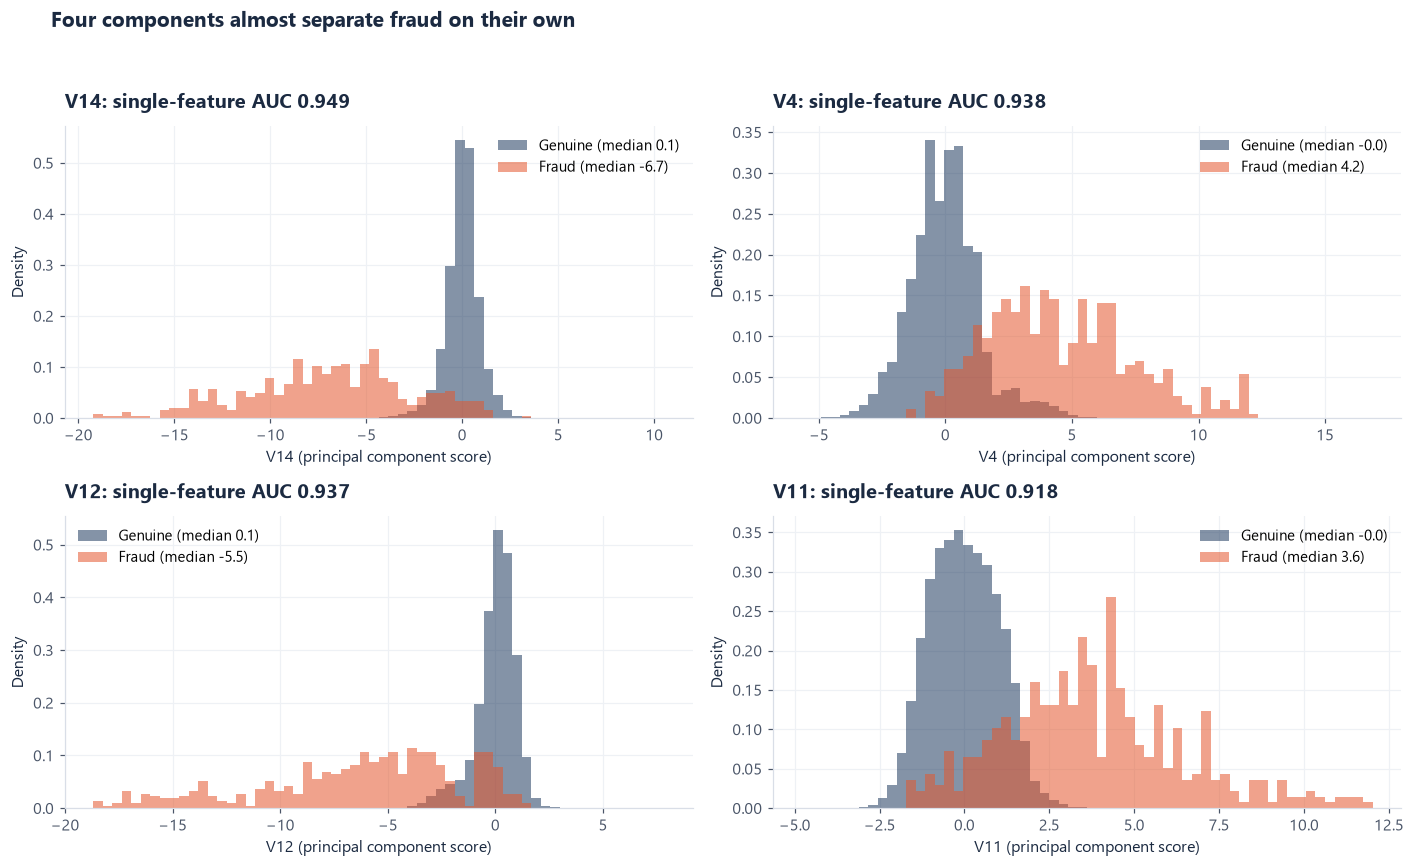

,single_feature_auc,direction,review
feature,,,
V14,0.9492,-,CHECK FOR LEAKAGE
V4,0.9383,+,CHECK FOR LEAKAGE
V12,0.9370,-,CHECK FOR LEAKAGE
V11,0.9181,+,CHECK FOR LEAKAGE
V10,0.9141,-,CHECK FOR LEAKAGE
V3,0.9121,-,CHECK FOR LEAKAGE
V2,0.8550,+,
V16,0.8471,-,
V9,0.8441,-,


In [21]:
sep = audit.leakage_screen(fr, F.V_COLS + ["Amount", "Hour"], "Class", flag_at=0.9)
top4 = list(sep.index[:4])
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.flat, top4):
    eda.dist_by_target(fr, col, "Class", ax=ax, clip=1.0, bins=60, labels=("Genuine", "Fraud"),
                       title=f"{col}: single-feature AUC {sep.loc[col, 'single_feature_auc']:.3f}")
    ax.set_xlabel(f"{col} (principal component score)")
fig.suptitle("Four components almost separate fraud on their own", x=0.04, ha="left", fontsize=14, fontweight="bold", color=PALETTE["ink"])
fig.tight_layout(rect=(0, 0, 1, 0.95)); plt.show()
sep.head(10)

Several components reach a single-feature AUC above 0.9. In most projects that is a leakage flag. Here it is the nature
of the features: the components are linear mixes of the transaction's own attributes, known at authorisation time.
There is one subtle look-ahead that cannot be removed: the data provider fitted the PCA on both days, so the rotation
itself has seen the test period. Any forward-in-time result on this data is therefore slightly optimistic, and the
notebooks say so.

### Is day 2 like day 1?

In [22]:
day1, day2 = fr[fr["Day"] == "Day 1"], fr[fr["Day"] == "Day 2"]
psi_day = eda.stability(day1, day2, F.V_COLS + ["Amount", "Hour"])
g = fr.groupby("Day")["Class"].agg(["sum", "count"])
lo, hi = eda.wilson(g["sum"], g["count"])
print(pd.DataFrame({"transactions": g["count"], "frauds": g["sum"], "fraud_rate": g["sum"] / g["count"], "ci_low": lo, "ci_high": hi}).to_string())
tr_m, te_m = F.fraud_split(fr)
psi_split = eda.stability(fr[tr_m], fr[te_m], F.V_COLS + ["Amount"])
print(f"\nPSI day 1 -> day 2: max {psi_day['psi'].max():.3f} ({psi_day.index[0]}); {(psi_day['status'] != 'stable').sum()} of {len(psi_day)} features above 0.10")
print(f"PSI training window (first ~31 h) -> test window: max {psi_split['psi'].max():.3f}; {(psi_split['status'] != 'stable').sum()} features above 0.10")
psi_day.head(6)

       transactions  frauds  fraud_rate  ci_low  ci_high
Day                                                     
Day 1        144786     281      0.0019  0.0017   0.0022
Day 2        140021     211      0.0015  0.0013   0.0017



PSI day 1 -> day 2: max 1.566 (V1); 15 of 30 features above 0.10
PSI training window (first ~31 h) -> test window: max 1.506; 16 features above 0.10


,psi,status
feature,,
V1,1.5663,shifted
V3,1.4253,shifted
V28,1.0464,shifted
V25,0.4397,shifted
V15,0.3994,shifted
V5,0.3537,shifted


Half the inputs shift between the two days, and three components shift a lot (PSI above 1). That is not a time-of-day
mix effect: comparing the same clock hours on both days gives the same PSI. Plotting the hourly median shows what is
going on.

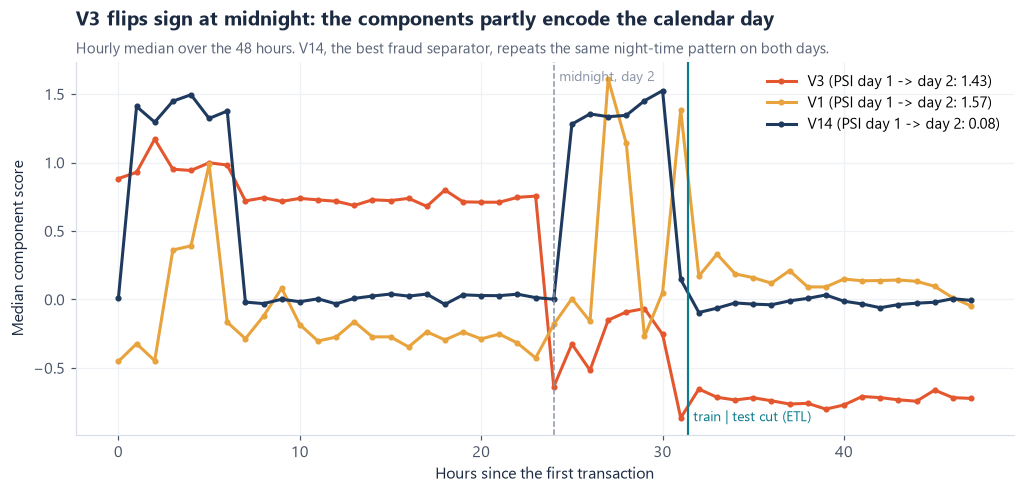

,same clock hours (10-20) on both days
V1,1.5447
V3,1.4760
V28,1.0315
V14,0.0951


In [23]:
habs = (fr["Time"] // 3600).astype(int)
med = fr.groupby(habs)[["V3", "V1", "V14"]].median()
fig, ax = plt.subplots(figsize=(11, 4.4))
for col, colr in zip(med.columns, (PALETTE["coral"], PALETTE["amber"], PALETTE["navy"])):
    ax.plot(med.index, med[col], marker="o", ms=3, color=colr, label=f"{col} (PSI day 1 -> day 2: {psi_day.loc[col, 'psi']:.2f})")
ax.axvline(24, color=PALETTE["grey"], lw=1, ls="--"); ax.text(24.3, ax.get_ylim()[1] * 0.92, "midnight, day 2", fontsize=9, color=PALETTE["grey"])
ax.axvline(F.FRAUD_CUT / 3600, color=PALETTE["teal"], lw=1.4); ax.text(F.FRAUD_CUT / 3600 + 0.3, ax.get_ylim()[0] * 0.9, "train | test cut (ETL)", fontsize=9, color=PALETTE["teal"])
ax.set(xlabel="Hours since the first transaction", ylabel="Median component score")
ax.legend(loc="upper right")
headline(ax, "V3 flips sign at midnight: the components partly encode the calendar day",
         "Hourly median over the 48 hours. V14, the best fraud separator, repeats the same night-time pattern on both days.")
_ = savefig(fig, "01-fraud-drift", FIG); plt.show()
pd.DataFrame({"same clock hours (10-20) on both days": {v: eda.psi(fr.loc[fr["Hour"].between(10, 20) & (fr["Day"] == "Day 1"), v],
                                                                  fr.loc[fr["Hour"].between(10, 20) & (fr["Day"] == "Day 2"), v]) for v in ["V1", "V3", "V28", "V14"]}})

* **V3's median sits near +0.75 in every hour of day 1 and near -0.72 in every hour of day 2.** The confidential inputs
  behind the PCA must include something calendar-related (a date, weekday or batch effect). It is a step change, not a
  gradual drift, and nothing in the public extract explains it.
* **The components that separate fraud are stable** (V14 PSI under 0.1). The shift sits mostly in components with
  little fraud signal, which limits the damage.
* **The ETL's cut at 113,000 seconds (~31.4 hours) puts the first seven hours of day 2 in training**, so the champion
  has already seen the day-2 regime. Notebook 03 tests the harder version (train on day 1 only) to show how much
  that helps.
* Fraud rates differ by day (0.19% vs 0.15%) but the intervals almost touch: two days are too few to call a trend.

## 5. What EDA changed in the plan

* **Treat status codes as categories, not numbers.** -2/-1/0 are three behaviours (inactive, paid in full, revolving) with
  default rates of 13%, 17% and 13%: not an ordered scale. The WoE scorecard bins them as categories; the tree models
  can split them freely; the monotone challenger constrains only features whose direction is not in doubt.
* **Expect month 1 to look different.** "One month late" exists only in September, so a feature built the same way for
  every month is not measuring the same thing each month. Recency features (September status) and history features
  (worst status, months late) are kept separate.
* **One characteristic per family in the scorecard.** Bills are near-duplicates and status months correlate with each
  other; the scorecard keeps the strongest of each family and requires every coefficient to have the expected sign.
* **Fairness check at the cutoff, not only exclusion.** Default rates differ by sex and age band and the limit carries
  some age signal, so notebook 02 reports approval rate, bad rate and adverse-impact ratio by group at the 525 cutoff.
* **Fraud: evaluate on precision-recall and a fixed analyst budget**, validate forward in time, include hour of day, and
  state that the provider's PCA has seen both days.
* **Fraud drift is a step, not a slope.** Monitoring needs a daily PSI per component (V3 would have fired an alert at
  PSI 1.4 on day 2), and notebook 03 measures how much the model degrades when it has not seen the new regime.

In [24]:
report.update_metrics(METRICS, "01_eda", {
    "credit_rows": len(u), "default_rate": float(y.mean()),
    "default_rate_2_months_late_sep": float(t_status.loc["2 months late", "rate"]),
    "monthly_cure_rate_past_due": float(cure),
    "iv_top": {k: float(v) for k, v in iv["iv"].head(5).items()},
    "proxy_auc_sex_from_behaviour": float(proxy_sex), "proxy_r2_age_from_behaviour": float(proxy_age),
    "fraud_rows": int(n), "fraud_frauds": int(n1), "fraud_rate": n1 / n,
    "fraud_duplicate_rows": int(fd["exact_duplicate_rows"]),
    "fraud_max_psi_day1_day2": float(psi_day["psi"].max())})["01_eda"]["default_rate"]

0.2212